# Where can BCA help a policy? A test in a two-step world

## Bottom line (written after the run)

- **BCA as the hosts use it today did not help where it matters.** The hosts turn BCA's width into extra caution at every action. Both versions of that did far worse than a simple rule that refuses actions the training data barely cover. Their regret was 0.43 and 0.38, against 0.12 for the simple rule. (Regret is the return lost against perfect choices; lower is better.) The width is measured where the data are, so it cannot see how the risky action turns out.
- **BCA helps as a gate.** A gate reads held-out outcomes of the risky action, then either lets it through or falls back to the safe action. Every gate that read those outcomes closed 38% to 87% of the distance between the simple rule and perfect choices. Feeding the gates shuffled outcomes removed the gain, so the gain comes from the outcomes themselves.
- **BCA's tail certificate improved return at almost no cost in safety.** Against the simple rule, it cut regret from 0.122 to 0.076. It took the risky action in an unsafe world in only 0.2% of cases; the simple rule never did.
- **Compare with the safe action's value.** The step-1 form of the gate compares the risky action with all other data plus a margin. In some worlds it let a harmful action through in up to 98% of seeds. Comparing with the safe action's value instead cut regret from 0.051 to 0.028.
- **For return, a plain average won; for safety, BCA's tail certificate won.** The plain average of the held-out outcomes had the lowest regret, 0.016. Among the gates, only BCA's tail certificate and its exact textbook twin kept the risky action rare in every unsafe world: at most 3% of seeds, against up to 38% for plain split conformal.
- **With equal weights, BCA is a textbook test.** It decided the same as the exact binomial test in 99.6% of cases; the rest were random-sampling slips. It cannot certify anything with fewer than 29 held-out outcomes.
- **Follow-up.** [bca_mean_gate_toy.ipynb](bca_mean_gate_toy.ipynb) tests a BCA gate that asks about the average outcome instead of the 90% share. When every gate was held to the same safety level, it earned the most.

**How to run:** open this notebook in the repository's `.venv` and choose Run All. It needs Python 3, NumPy and Matplotlib, and takes under a minute. Nothing is downloaded and nothing from the repository is imported.

Everything here is a toy, run on toy seeds only, with no ThrusterChain seeds. The kill rules (the results that would shelve each idea) were written before the first run and fingerprinted.

## Why this notebook

[bca_discrete_toy.ipynb](bca_discrete_toy.ipynb) found that BCA's width, used as a penalty, improved no decision. This notebook asks: **is there any way BCA's calibrated errors can change a decision for the better, where simpler rules cannot?**

It changes four things from the first notebook, so that a good rule has something to find:

1. **The log holds a few tries of the risky action.** They are held out: the critic never trains on them, and only the safeguards read them. The first notebook had none, so no rule could tell its worlds apart.
2. **The critic makes the same guess in every world.** It values the risky action at about 1.5, against 1.0 for the safe one, as a neural critic might by generalizing from other states. Whether that guess is right depends on the world.
3. **Ten worlds instead of two.** In some the risky action is truly better; in others it is worse, by up to 4.6. It goes wrong in one of two ways: every outcome a bit worse (**shortfall**), or a rare catastrophe (**tail**).
4. **Rewards are noisy,** so no two scores tie, and the width's scale reflects how noisy each cell is.

## Words used

- **Safe** and **venture:** the two actions. The safe action is the **fallback**.
- **Gap:** venturing at the last step in context 1. The critic wants this, but no training row covers it.
- **Survivors:** the held-out tries of the gap action. Their number (5 to 100) is the **evidence size**.
- **Claimed advantage:** how much better the critic thinks venture is than safe at the gap (about 0.5).
- **Over-prediction score:** the critic's value minus what a row actually got. Positive means the critic expected too much.
- **Regret:** expected return lost against the best possible choices, computed exactly at the deployment mix of contexts. 0 is perfect.
- **Room:** the regret of the best simple rule (refusing thin data: 0.1215). A rule's **gain** is the share of the room it closes.
- **Unsafe world:** a world where more than 10% of venture's outcomes at the gap fall below safe's average of 1.0.
- **Unsafe-deviation rate:** how often a rule ventures at the gap in unsafe worlds.
- **World-blind rule:** a rule that never reads the survivors' outcomes.

In [1]:
import math, time, hashlib
from fractions import Fraction
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
START = time.perf_counter()

ALPHA, BETA, DRAWS = 0.1, 0.95, 1000        # BCA settings as in production
SIGMA = 0.2                                 # sd of the Gaussian noise on every reward
P_LOG = np.array([0.85, 0.15])              # context mix in the log
P_TEST = np.array([0.35, 0.65])             # context mix at deployment
N_LOG, TRAIN_SHARE, N_MIN = 1800, 2 / 3, 20
EVIDENCE = (5, 10, 20, 30, 45, 60, 100)     # survivors available to calibration
ADVANTAGE = (1.0, 0.5, 0.25, 0.1, -0.1, -0.25, -0.5, -1.0, -2.0, -4.6)
HARMS = ("shortfall", "tail")
N_SEEDS, ROOT_SEED = 200, 20261014
MARGIN = 0.10                               # step-1 certificate margin, value units
GAIN = 1.0                                  # A1: critic minus GAIN x width
BC_WEIGHT, BLEND = 0.4, 0.5                 # host BC weight; A2 multiplier 1 + BLEND x U / (U + unit)
SAFE, VENTURE = 0, 1
CATASTROPHE = -5.0
A_FRAC, B_FRAC = Fraction(str(ALPHA)), Fraction(str(BETA))
assert max(EVIDENCE) <= 100 and 0 < ALPHA < 1 and 0 < BETA < 1

## The toy world

There are two steps (t = 0, 1) and two contexts (0, 1). At each step the policy picks safe or venture. The table gives each choice's average reward and where it leads.

| t | context | safe | venture | next |
|---|---|---|---|---|
| 0 | 0 | 0.1 | 0.3 | (1, 0) |
| 0 | 1 | 0.1 | −0.5 or 1.1, half each | (1, 1) |
| 1 | 0 | 1 | 0 or 3, half each | end |
| 1 | 1 | 1 | **the gap.** Shortfall: 1 + advantage. Tail: −5 with probability (1 − advantage)/7, else 2 | end |

- Every reward also gets random noise with spread 0.2.
- Context 1 is rare in the log (15%) but common at deployment (65%).
- The logged behavior ventures half the time at t = 0, a quarter of the time at t = 1 in context 0, and never at the gap.
- Separately, the log holds up to 100 survivors at the gap. Only the safeguards read them.
- All worlds share the same log and the same random numbers behind the survivors. Only the gap's outcome law differs between them.

In [2]:
def gap_law(harm, adv):
    """Outcome law of venture at (t=1, context 1) as (probability, mean) pairs; noise is added on top."""
    if harm == "shortfall":
        return [(1.0, 1.0 + adv)]
    p = (1.0 - adv) / 7.0                       # mean 2 - 7p = 1 + adv
    return [(p, CATASTROPHE), (1.0 - p, 2.0)]

def law(t, c, a, harm="tail", adv=-4.6):
    if t == 0:
        if a == SAFE: return [(1.0, 0.1)]
        return [(1.0, 0.3)] if c == 0 else [(0.5, -0.5), (0.5, 1.1)]
    if a == SAFE: return [(1.0, 1.0)]
    if c == 0: return [(0.5, 0.0), (0.5, 3.0)]
    return gap_law(harm, adv)

def mean_of(t, c, a, harm="tail", adv=-4.6):
    return sum(p * m for p, m in law(t, c, a, harm, adv))

def phi(x):
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

def below_safe(harm, adv):
    """Exact probability that a gap outcome falls below safe's mean, 1.0."""
    return sum(p * phi((1.0 - m) / SIGMA) for p, m in gap_law(harm, adv))

def draw(lawlist, u, z):
    """Inverse-CDF draw from shared uniforms u and normals z, so every world reuses the same random numbers."""
    cum = np.cumsum([p for p, _ in lawlist])
    k = np.minimum(np.searchsorted(cum, u, side="right"), len(lawlist) - 1)
    return np.array([m for _, m in lawlist])[k] + SIGMA * z

def collect(seed):
    rng = np.random.default_rng([ROOT_SEED, seed])
    c = rng.choice(2, N_LOG, p=P_LOG)
    a = np.zeros((N_LOG, 2), dtype=int)
    a[:, 0] = rng.random(N_LOG) < 0.5
    a[:, 1] = (c == 0) & (rng.random(N_LOG) < 0.25)
    u, z = rng.random((N_LOG, 2)), rng.standard_normal((N_LOG, 2))
    r = np.zeros((N_LOG, 2))
    for t in range(2):
        for cc in range(2):
            for aa in range(2):
                m = (c == cc) & (a[:, t] == aa)
                if m.any(): r[m, t] = draw(law(t, cc, aa), u[m, t], z[m, t])
    train = rng.random(N_LOG) < TRAIN_SHARE
    split = lambda m: {"c": c[m], "a": a[m], "r": r[m]}
    survivors = {"u": rng.random(100), "z": rng.standard_normal(100)}
    return split(train), split(~train), survivors

def survivor_rewards(surv, harm, adv, n):
    return draw(gap_law(harm, adv), surv["u"][:n], surv["z"][:n])

## The critic and the width's scale

Both are fitted on training rows only, then frozen before any safeguard looks at the survivors.

- **Critic.** It uses each cell's average where the cell has at least 20 training rows. Elsewhere it guesses that venture's advantage in context 0 also holds in context 1. At the gap, this gives about 1.5 for venture against 1.0 for safe.
- **Width's scale.** Each cell's spread of training errors, pulled toward the overall spread.

In [3]:
def targets(data, t, q):
    y = data["r"][:, t].copy()
    if t == 0: y += q[1, data["c"], SAFE]
    return y

def fit_critic(train):
    """Stage 1: cell means where a cell has at least N_MIN rows, else the additive guess
    Q(c, a) = Q(c, safe) + Q(other c, a) - Q(other c, safe). Stage 0: targets r0 + Q(1, c, safe)."""
    q, n = np.zeros((2, 2, 2)), np.zeros((2, 2, 2), dtype=int)
    for t in (1, 0):
        y = targets(train, t, q)
        for c in range(2):
            for a in range(2):
                m = (train["c"] == c) & (train["a"][:, t] == a)
                n[t, c, a] = m.sum()
                if n[t, c, a] >= N_MIN: q[t, c, a] = y[m].mean()
        for c in range(2):
            for a in range(2):
                if n[t, c, a] < N_MIN:
                    o = 1 - c
                    assert t == 1 and min(n[1, c, SAFE], n[1, o, a], n[1, o, SAFE]) >= N_MIN
                    q[1, c, a] = q[1, c, SAFE] + q[1, o, a] - q[1, o, SAFE]
    return q, n

def fit_scale(train, q):
    """Per-cell residual sd from training rows, shrunk toward the stage's pooled sd with 5 pseudo-rows."""
    scale, unit = np.zeros((2, 2, 2)), np.zeros(2)
    for t in range(2):
        res = targets(train, t, q) - q[t, train["c"], train["a"][:, t]]
        pooled, unit[t] = res.var(), res.std()
        for c in range(2):
            for a in range(2):
                m = (train["c"] == c) & (train["a"][:, t] == a)
                k = int(m.sum()); v = res[m].var() if k > 1 else 0.0
                scale[t, c, a] = max(0.05, math.sqrt((k * v + 5 * pooled) / (k + 5)))
    return scale, unit

## BCA's threshold, and its textbook twin

`bca` re-implements production BCA (`calibration/wbcp.py`), with equal weights as in production.

With equal weights, BCA gives the same answer as a textbook test, the **exact binomial test**. BCA certifies a threshold with x of n scores above it exactly when P(Binomial(n, 0.1) ≤ x) ≤ 0.05. `bca_exact` computes that exact answer, and the table below checks BCA's random sampler against it.

Nothing can be certified with fewer than 29 scores. Even 0 of 28 scores above the threshold fails the test, because 0.9^28 = 0.052 is above 0.05.

In [4]:
def crossings_of(s, exps):
    n = s.size
    mass = exps[:, :n]
    total = mass.sum(axis=1) + exps[:, n]
    covered = np.cumsum(mass, axis=1) >= (1 - ALPHA) * total[:, None]
    return np.where(covered.any(axis=1), s[covered.argmax(axis=1)], np.inf)

def bca(scores, exps):
    """Uniform-weight BCA: (threshold max(lambda_hat, lambda_hpd), sorted per-draw crossings).
    exps: standard exponentials, one row per draw; the first n columns go to the sorted scores, column n to the
    test atom. Reusing exps across worlds pairs their Monte Carlo noise."""
    s = np.sort(np.asarray(scores, dtype=float)); n = s.size
    assert n >= 1 and np.all(np.isfinite(s)) and exps.shape[1] > n
    cross = np.sort(crossings_of(s, exps))
    lam_hat = s[math.ceil((1 - A_FRAC) * n) - 1]
    lam_hpd = cross[math.ceil(B_FRAC * len(cross)) - 1]
    return max(lam_hat, lam_hpd), cross

def bca_many(scores, rng, draws, chunk=5000):
    s = np.sort(np.asarray(scores, dtype=float))
    cross = np.sort(np.concatenate([crossings_of(s, rng.standard_exponential((min(chunk, draws - k), s.size + 1)))
                                    for k in range(0, draws, chunk)]))
    return max(s[math.ceil((1 - A_FRAC) * s.size) - 1], cross[math.ceil(B_FRAC * draws) - 1])

def log_pmf(x, n, p):
    return (math.lgamma(n + 1) - math.lgamma(x + 1) - math.lgamma(n - x + 1)
            + x * math.log(p) + (n - x) * math.log1p(-p))

def binom_cdf(x, n, p):
    return 0.0 if x < 0 else min(1.0, sum(math.exp(log_pmf(i, n, p)) for i in range(min(x, n) + 1)))

@lru_cache(maxsize=None)
def certified_above(n):
    """Largest x with P(Binomial(n, ALPHA) <= x) <= 1 - BETA, or -1 when even x = 0 fails."""
    cdf, best = 0.0, -1
    for x in range(n + 1):
        cdf += math.exp(log_pmf(x, n, ALPHA))
        if cdf > 1 - BETA: break
        best = x
    return best

def bca_exact(scores):
    """BCA's threshold with infinitely many draws: the training-conditional split-conformal bound."""
    s = np.sort(np.asarray(scores, dtype=float)); n = s.size
    x = certified_above(n)
    hpd = s[n - x - 1] if x >= 0 else math.inf
    return max(s[math.ceil((1 - A_FRAC) * n) - 1], hpd)

rng = np.random.default_rng([ROOT_SEED, 999])
print("n    BCA with 1,000 draws = exact    BCA with 100,000 draws = exact    (8 random score sets each)")
for n in (10, 28, 29, 30, 36, 45, 100):
    a = b = 0
    for _ in range(8):
        s = rng.standard_normal(n) * rng.uniform(0.5, 2.0)
        ex = bca_exact(s)
        a += bca(s, rng.standard_exponential((1000, n + 1)))[0] == ex
        b += bca_many(s, rng, 100_000) == ex
    print(f"{n:3d}  {a:>14d}/8  {b:>30d}/8")
print("Smallest n with any finite threshold:", next(n for n in range(1, 200) if certified_above(n) >= 0))

n    BCA with 1,000 draws = exact    BCA with 100,000 draws = exact    (8 random score sets each)
 10               8/8                               8/8
 28               4/8                               8/8
 29               4/8                               8/8
 30               7/8                               8/8
 36               8/8                               8/8
 45               5/8                               8/8
100               8/8                               8/8
Smallest n with any finite threshold: 29


## The rules compared

Every rule uses the same frozen critic. The gates change only the gap decision: venture or fall back. The width rules and the host actor can change other decisions too.

| Label | Plain name | What it does |
|---|---|---|
| greedy | no safeguard | takes the critic's best action everywhere |
| range limit | refuse thin data | falls back wherever the critic's choice has fewer than 20 training rows |
| count penalty | count penalty | subtracts 1/√(training rows + 1) from the critic's value |
| host BC actor | pull toward the log | subtracts 0.4 × a penalty for leaving the logged action (a discrete TD3+BC) |
| A1 | BCA width penalty | subtracts BCA's width (threshold × scale) from the critic's value at every action; the threshold uses all held-out rows, survivors included |
| A2 | BCA width in the host | the host actor with production BCA's multiplier on its pull toward the log, as in `calibration/dose.py`; this is how the hosts use BCA today |
| G1 | step-1 gate | the restructure's step-1 rule: falls back if BCA is 95% sure that the survivors' over-predictions exceed those of all other last-step rows by more than 0.10 |
| G1 local reference | step-1 gate, local | the same, comparing only with context-1 rows (information only) |
| G2R | BCA harm test | falls back only if BCA is 95% sure that more than 10% of outcomes fall below the critic's value of safe |
| G2 | BCA tail certificate | ventures only if BCA is 95% sure that at least 90% of outcomes beat the critic's value of safe |
| G3 | split-conformal certificate | G2 with the usual conformal rank instead of BCA |
| G4 | exact binomial certificate | G2 computed with the exact binomial test |
| G5 | plain average ("plug-in mean") | ventures if the survivors' average reward is at least the critic's value of safe; the same as refitting the gap cell from the survivors |
| G6 | t-test harm test | falls back only if a one-sided 95% t-test says the survivors' average is below the critic's value of safe |
| oracle switch | oracle | knows the world and picks the better action at the gap; regret 0 |
| G1, G2R, G2 shuffled | controls | the same rules, fed a random set of other held-out rows of the same size instead of the survivors |

The first four rules are **world-blind**. A1 and A2 use BCA as built, as a width at every action. The G rules are **gates**: they read the survivors' outcomes.

## What would shelve each idea

The next cell holds the exact kill rules, written and fingerprinted before the first run. Here they are in plain words; this summary was added after the run, and the rules themselves decide.

- **Test 1, BCA's width as built.** Shelve A1, and separately A2, if it closes less than a quarter of the room.
- **Test 2, the step-1 gate (G1).** Shelve it if it closes less than half the room, or if shuffled outcomes keep more than half its gain.
- **Test 3, what to compare with.** Shelve "compare with the critic's claimed advantage" if the BCA harm test (G2R) does not have lower regret than the step-1 gate.
- **Test 4, what is BCA's own.**
  - (a) Shelve "BCA decides differently from the exact binomial test" if the two agree in at least 99% of cases.
  - (b) Shelve "BCA's confidence makes deviations safer than plain split conformal" if split conformal's unsafe-deviation rate is less than 5 points higher than BCA's.
  - (c) Shelve "safety needs a quantile, not an average" if the plain average's unsafe-deviation rate in tail-shape unsafe worlds is less than 5 points higher than BCA's.

In [5]:
KILL_RULES = """
Written before the first run of this notebook. Not to be changed after seeing results.

Shared definitions. Regret: the best exact expected return at the deployment context mix minus the rule's.
Pooled regret: the mean over 200 toy seeds, both harm shapes, the 10 worlds of the advantage ladder and the
7 evidence sizes. Best world-blind rule: whichever of greedy, range limit, count penalty and host BC actor has
the lowest pooled regret. Room: its pooled regret minus the oracle switch's. Gain of a rule: the best
world-blind rule's pooled regret minus the rule's. Unsafe world: a venture outcome at the gap falls below
safe's mean (1.0) with probability above ALPHA. Unsafe-deviation rate: the share of (seed, evidence size)
cases in unsafe worlds where the rule takes venture at the gap.

Test 1, channel A (BCA's width at every action, as built). Shelve A1, and separately A2, if its gain is below
a quarter of the room.

Test 2, channel B (outcome gate, step-1 form G1). Shelve if G1's gain is below half of the room, or if
"G1 shuffled" keeps more than half of G1's gain.

Test 3, the decision-referenced reference point. Shelve "comparing with the critic's own claimed advantage
beats a fixed margin against the rest" if G2R's pooled regret is not below G1's.

Test 4, which parts are BCA's own. Each claim is shelved on its own:
(a) "BCA's posterior decides differently from the exact binomial test": shelved if G2 and G4 agree in at
    least 99% of all cases.
(b) "BCA's credibility makes deviations safer than plain split conformal": shelved if G3's unsafe-deviation
    rate is less than 5 percentage points above G2's, pooled over unsafe worlds and evidence sizes.
(c) "Tail safety needs BCA's quantile semantics, not a mean": shelved if G5's unsafe-deviation rate is less
    than 5 percentage points above G2's in unsafe tail-shape worlds.
Reported, not deciding: G2's return cost against G5, and G2's worst per-world unsafe-deviation rate
(theory: at most 1 - BETA = 5% with exact arithmetic, plus Monte Carlo and seed noise).
"""
print("Kill rules SHA-256:", hashlib.sha256(KILL_RULES.encode()).hexdigest())

Kill rules SHA-256: bb9e03252e9c6be5fc30e72d1172a134498198559d30f51d9552fd86a6afdbc3


## Run

The first cell below turns each rule into a decision for every world and evidence size. The second runs 200 seeds and prints sanity values over seeds:
- `claimed`: the claimed advantage;
- `q_gap` and `q_safe`: the critic's values at the gap;
- `r0`, `r1_min` and `r1_max`: BCA's width thresholds at the two steps;
- `n_rest`: the size of the step-1 gate's comparison group.

In [6]:
METHODS = ["oracle switch", "greedy", "range limit", "count penalty", "host BC actor",
           "A1 width penalty", "A2 width BC multiplier",
           "G1 step-1 certificate", "G1 local reference", "G2R BCA harm test", "G2 BCA tail certificate",
           "G3 split-conformal certificate", "G4 exact binomial certificate", "G5 plug-in mean",
           "G6 mean harm test", "G1 shuffled", "G2R shuffled", "G2 shuffled"]
WORLD_BLIND = ["greedy", "range limit", "count penalty", "host BC actor"]
GATES = [m for m in METHODS if m.startswith("G")]
M = {m: i for i, m in enumerate(METHODS)}
SWEEP = (0.0, 0.05, 0.10, 0.25, 0.5, 1.0)          # information only: G1 at other margins
K05 = math.ceil(Fraction(5, 100) * DRAWS * DRAWS)
ADV = np.array(ADVANTAGE)

MU = np.array([[[mean_of(t, c, a) for a in range(2)] for c in range(2)] for t in range(2)])

def regret(pi, adv):
    mu = MU.copy(); mu[1, 1, VENTURE] = 1.0 + adv
    got = np.take_along_axis(mu, pi[..., None], axis=-1)[..., 0]
    return float(((mu.max(axis=-1) - got) * P_TEST[None, :]).sum())

def bc_policy(q, n, dose):
    beta_hat = n / n.sum(axis=-1, keepdims=True)
    leave = (beta_hat * dose).sum(axis=-1, keepdims=True) - beta_hat * dose   # recorded mass on other actions
    return (q - BC_WEIGHT * leave).argmax(axis=-1)

def t95(df):
    z = 1.6448536269514722                       # one-sided 95% t quantile, Cornish-Fisher expansion
    return (z + (z**3 + z) / (4 * df) + (5 * z**5 + 16 * z**3 + 3 * z) / (96 * df**2)
            + (3 * z**7 + 19 * z**5 + 17 * z**3 - 15 * z) / (384 * df**3))

def step1_off(cross_gap, cross_ref, margin):
    """True when the step-1 certificate stays off: the 5% quantile of (gap crossing - reference crossing)
    over all DRAWS x DRAWS pairs is at most the margin."""
    return np.searchsorted(cross_gap, margin + cross_ref, side="right").sum() >= K05

def run_seed(seed):
    train, cal, surv = collect(seed)
    q, n = fit_critic(train)
    scale, unit = fit_scale(train, q)
    greedy = q.argmax(axis=-1)
    assert n[1, 1, VENTURE] == 0 and greedy[1, 1] == VENTURE
    claimed = q[1, 1, VENTURE] - q[1, 1, SAFE]
    rng = np.random.default_rng([ROOT_SEED, seed, 1])
    e_gap = rng.standard_exponential((DRAWS, max(EVIDENCE) + 1))
    s_rest = q[1, cal["c"], cal["a"][:, 1]] - cal["r"][:, 1]
    cross_rest = bca(s_rest, rng.standard_exponential((DRAWS, s_rest.size + 1)))[1]
    s_local = s_rest[cal["c"] == 1]
    # About 90 local rows: a draw can fail to cross (+inf); step1_off then counts its pairs as at most the margin.
    cross_local = bca(s_local, rng.standard_exponential((DRAWS, s_local.size + 1)))[1]
    assert np.all(np.isfinite(cross_rest))
    a0, a1 = cal["a"][:, 0], cal["a"][:, 1]
    r0 = bca_exact(np.abs(targets(cal, 0, q) - q[0, cal["c"], a0]) / scale[0, cal["c"], a0])
    bank1 = np.abs(s_rest) / scale[1, cal["c"], a1]
    fixed = {"greedy": greedy,
             "range limit": np.where(n >= N_MIN, q, -np.inf).argmax(axis=-1),
             "count penalty": (q - GAIN / np.sqrt(n + 1)).argmax(axis=-1),
             "host BC actor": bc_policy(q, n, np.ones_like(q))}
    shuffle = np.random.default_rng([ROOT_SEED, seed, 2])
    reg = np.zeros((len(EVIDENCE), len(HARMS), len(ADVANTAGE), len(METHODS)))
    dev = np.zeros(reg.shape, dtype=bool)
    sweep = np.zeros((len(EVIDENCE), len(HARMS), len(ADVANTAGE), len(SWEEP)), dtype=bool)
    r1_seen = []
    for i, ne in enumerate(EVIDENCE):
        order = shuffle.permutation(s_rest.size + ne)
        rank = math.ceil((ne + 1) * (1 - A_FRAC))
        for h, harm in enumerate(HARMS):
            for w, adv in enumerate(ADVANTAGE):
                s_gap = q[1, 1, VENTURE] - survivor_rewards(surv, harm, adv, ne)
                thr, cross = bca(s_gap, e_gap)
                thr_f, cross_f = bca(np.concatenate([s_gap, s_rest])[order[:ne]], e_gap)
                above = int((s_gap > claimed).sum())
                venture = {
                    "G1 step-1 certificate": step1_off(cross, cross_rest, MARGIN),
                    "G1 local reference": step1_off(cross, cross_local, MARGIN),
                    "G2R BCA harm test": np.searchsorted(cross, claimed, side="right") >= (1 - B_FRAC) * DRAWS,
                    "G2 BCA tail certificate": thr <= claimed,
                    "G3 split-conformal certificate": rank <= ne and np.sort(s_gap)[rank - 1] <= claimed,
                    "G4 exact binomial certificate": binom_cdf(above, ne, ALPHA) <= 1 - BETA,
                    "G5 plug-in mean": s_gap.mean() <= claimed,
                    "G6 mean harm test": s_gap.mean() - t95(ne - 1) * s_gap.std(ddof=1) / math.sqrt(ne) <= claimed,
                    "G1 shuffled": step1_off(cross_f, cross_rest, MARGIN),
                    "G2R shuffled": np.searchsorted(cross_f, claimed, side="right") >= (1 - B_FRAC) * DRAWS,
                    "G2 shuffled": thr_f <= claimed}
                pol = dict(fixed)
                for name, go in venture.items():
                    pi = greedy.copy(); pi[1, 1] = VENTURE if go else SAFE; pol[name] = pi
                mu = MU.copy(); mu[1, 1, VENTURE] = 1.0 + adv
                pol["oracle switch"] = mu.argmax(axis=-1)
                r1 = bca_exact(np.concatenate([bank1, np.abs(s_gap) / scale[1, 1, VENTURE]]))
                r1_seen.append(r1)
                width = np.stack([r0 * scale[0], r1 * scale[1]])
                assert np.all(np.isfinite(width))
                pol["A1 width penalty"] = (q - GAIN * width).argmax(axis=-1)
                pol["A2 width BC multiplier"] = bc_policy(q, n, 1 + BLEND * width / (width + unit[:, None, None]))
                for name, pi in pol.items():
                    reg[i, h, w, M[name]] = regret(pi, adv)
                    dev[i, h, w, M[name]] = pi[1, 1] == VENTURE
                sweep[i, h, w] = [step1_off(cross, cross_rest, m) for m in SWEEP]
    info = dict(claimed=claimed, q_gap=q[1, 1, VENTURE], q_safe=q[1, 1, SAFE], r0=r0,
                r1_min=min(r1_seen), r1_max=max(r1_seen), n_rest=s_rest.size)
    return reg, dev, sweep, info

In [7]:
T0 = time.perf_counter()
REG = np.zeros((N_SEEDS, len(EVIDENCE), len(HARMS), len(ADVANTAGE), len(METHODS)))
DEV = np.zeros(REG.shape, dtype=bool)
SWP = np.zeros((N_SEEDS, len(EVIDENCE), len(HARMS), len(ADVANTAGE), len(SWEEP)), dtype=bool)
INFO = []
for seed in range(N_SEEDS):
    REG[seed], DEV[seed], SWP[seed], info = run_seed(seed)
    INFO.append(info)
print(f"{N_SEEDS} seeds in {time.perf_counter() - T0:.1f} s")
for key in ("claimed", "q_gap", "q_safe", "r0", "r1_min", "r1_max", "n_rest"):
    v = np.array([d[key] for d in INFO], dtype=float)
    print(f"{key:8} mean {v.mean():8.3f}   min {v.min():8.3f}   max {v.max():8.3f}")

200 seeds in 20.9 s
claimed  mean    0.504   min    0.256   max    0.788
q_gap    mean    1.506   min    1.242   max    1.788
q_safe   mean    1.002   min    0.962   max    1.039
r0       mean    1.712   min    1.511   max    1.960
r1_min   mean    1.473   min    1.292   max    1.648
r1_max   mean    8.896   min    8.093   max    9.934
n_rest   mean  600.655   min  546.000   max  659.000


## Results

**How to read the first table.** The first lines show how often venture's outcome at the gap falls below 1.0 in each world; above 0.10 makes a world unsafe. Then there is one row per rule, pooled over everything:

- **pooled regret:** lower is better; 0 is perfect.
- **gain / room:** 1 is as good as the oracle, 0 is no better than refusing thin data, and below 0 is worse.
- **unsafe-deviation:** how often the rule ventured at the gap in unsafe worlds. Lower is safer.
- **(tail worlds):** the same, in tail-shape unsafe worlds only.

In [8]:
UNSAFE = np.array([[below_safe(h, a) > ALPHA for a in ADVANTAGE] for h in HARMS])          # (harm, world)
unsafe_mask = np.broadcast_to(UNSAFE[None, None], DEV.shape[:4])
tail_mask = unsafe_mask.copy(); tail_mask[:, :, HARMS.index("shortfall")] = False
pooled = REG.mean(axis=(0, 1, 2, 3))
best_wb = min(WORLD_BLIND, key=lambda m: pooled[M[m]])
room = pooled[M[best_wb]] - pooled[M["oracle switch"]]
gain = {m: pooled[M[best_wb]] - pooled[M[m]] for m in METHODS}
unsafe_rate = {m: DEV[..., M[m]][unsafe_mask].mean() for m in METHODS}
unsafe_tail = {m: DEV[..., M[m]][tail_mask].mean() for m in METHODS}

print("P(venture outcome at the gap < 1.0), by world; above 0.10 is an unsafe world:")
for harm in HARMS:
    print(f"  {harm:9}", "  ".join(f"{a:+.2f}: {below_safe(harm, a):.3f}" for a in ADVANTAGE))
print(f"\nBest world-blind rule: {best_wb}.  Room = {room:.4f} (its pooled regret minus the oracle's)\n")
print(f"{'rule':31} {'pooled regret':>13} {'gain / room':>11} {'unsafe-deviation':>17} {'(tail worlds)':>14}")
for m in METHODS:
    print(f"{m:31} {pooled[M[m]]:13.4f} {gain[m] / room:11.2f} {unsafe_rate[m]:17.3f} {unsafe_tail[m]:14.3f}")

P(venture outcome at the gap < 1.0), by world; above 0.10 is an unsafe world:
  shortfall +1.00: 0.000  +0.50: 0.006  +0.25: 0.106  +0.10: 0.309  -0.10: 0.691  -0.25: 0.894  -0.50: 0.994  -1.00: 1.000  -2.00: 1.000  -4.60: 1.000
  tail      +1.00: 0.000  +0.50: 0.071  +0.25: 0.107  +0.10: 0.129  -0.10: 0.157  -0.25: 0.179  -0.50: 0.214  -1.00: 0.286  -2.00: 0.429  -4.60: 0.800

Best world-blind rule: range limit.  Room = 0.1215 (its pooled regret minus the oracle's)

rule                            pooled regret gain / room  unsafe-deviation  (tail worlds)
oracle switch                          0.0000        1.00             0.250          0.250
greedy                                 0.5505       -3.53             1.000          1.000
range limit                            0.1215        0.00             0.000          0.000
count penalty                          0.1222       -0.01             0.000          0.000
host BC actor                          0.4939       -3.06             0.8

**Verdicts.** Each line gives a test's bar, its result, and ALIVE or SHELVED. The last lines are reported but decide nothing.

In [9]:
def verdict(shelved):
    return "SHELVED" if shelved else "ALIVE"

print("Test 1, width channel (bar: gain at least 0.25 of the room)")
for m in ("A1 width penalty", "A2 width BC multiplier"):
    print(f"  {m}: gain / room = {gain[m] / room:+.2f} -> {verdict(gain[m] < 0.25 * room)}")
g1, g1s = gain["G1 step-1 certificate"], gain["G1 shuffled"]
kept = g1s / g1 if g1 > 0 else float("nan")
print("Test 2, step-1 gate (bars: gain at least 0.50 of the room; shuffled keeps at most half)")
print(f"  gain / room = {g1 / room:+.2f}; shuffled keeps {kept:+.2f} of it -> {verdict(g1 < 0.5 * room or g1s > 0.5 * g1)}")
p2r, p1 = pooled[M["G2R BCA harm test"]], pooled[M["G1 step-1 certificate"]]
print("Test 3, decision-referenced reference point (bar: G2R's pooled regret below G1's)")
print(f"  G2R {p2r:.4f} against G1 {p1:.4f} -> {verdict(p2r >= p1)}")
agree = (DEV[..., M["G2 BCA tail certificate"]] == DEV[..., M["G4 exact binomial certificate"]]).mean()
print("Test 4a, 'BCA's posterior decides differently from the exact binomial test' (shelved if agreement >= 0.99)")
print(f"  agreement {agree:.4f} -> {verdict(agree >= 0.99)}")
d_b = unsafe_rate["G3 split-conformal certificate"] - unsafe_rate["G2 BCA tail certificate"]
print("Test 4b, 'BCA's credibility makes deviations safer than split conformal' (bar: 0.05 more unsafe deviations)")
print(f"  split conformal {unsafe_rate['G3 split-conformal certificate']:.3f} against BCA "
      f"{unsafe_rate['G2 BCA tail certificate']:.3f} (difference {d_b:+.3f}) -> {verdict(d_b < 0.05)}")
d_c = unsafe_tail["G5 plug-in mean"] - unsafe_tail["G2 BCA tail certificate"]
print("Test 4c, 'tail safety needs quantile semantics, not a mean' (bar: 0.05, tail-shape unsafe worlds)")
print(f"  plug-in mean {unsafe_tail['G5 plug-in mean']:.3f} against BCA {unsafe_tail['G2 BCA tail certificate']:.3f} "
      f"(difference {d_c:+.3f}) -> {verdict(d_c < 0.05)}")
print("Reported, not deciding:")
print(f"  G2's pooled regret minus G5's: {pooled[M['G2 BCA tail certificate']] - pooled[M['G5 plug-in mean']]:+.4f}")
for name in ("G2 BCA tail certificate", "G4 exact binomial certificate"):
    worst = [DEV[:, i, :, :, M[name]].mean(axis=0)[UNSAFE].max() for i in range(len(EVIDENCE))]
    print(f"  {name}: worst unsafe-world deviation rate by evidence size:",
          "  ".join(f"n={ne}: {v:.3f}" for ne, v in zip(EVIDENCE, worst)))

Test 1, width channel (bar: gain at least 0.25 of the room)
  A1 width penalty: gain / room = -2.50 -> SHELVED
  A2 width BC multiplier: gain / room = -2.09 -> SHELVED
Test 2, step-1 gate (bars: gain at least 0.50 of the room; shuffled keeps at most half)
  gain / room = +0.58; shuffled keeps -4.44 of it -> ALIVE
Test 3, decision-referenced reference point (bar: G2R's pooled regret below G1's)
  G2R 0.0282 against G1 0.0508 -> ALIVE
Test 4a, 'BCA's posterior decides differently from the exact binomial test' (shelved if agreement >= 0.99)
  agreement 0.9961 -> SHELVED
Test 4b, 'BCA's credibility makes deviations safer than split conformal' (bar: 0.05 more unsafe deviations)
  split conformal 0.057 against BCA 0.002 (difference +0.055) -> ALIVE
Test 4c, 'tail safety needs quantile semantics, not a mean' (bar: 0.05, tail-shape unsafe worlds)
  plug-in mean 0.290 against BCA 0.002 (difference +0.288) -> ALIVE
Reported, not deciding:
  G2's pooled regret minus G5's: +0.0601
  G2 BCA tail ce

**Breakdowns.** The same measures, split by the number of survivors. The last block shows how often a rule's gap decision changes at all across the ten worlds. A rule whose decision never changes cannot be reading the outcomes. For information, the step-1 gate is also shown at other margins.

In [10]:
show = ["greedy", "range limit", "count penalty", "host BC actor", "A1 width penalty", "A2 width BC multiplier",
        "G1 step-1 certificate", "G1 local reference", "G2R BCA harm test", "G2 BCA tail certificate",
        "G3 split-conformal certificate", "G5 plug-in mean", "G6 mean harm test", "oracle switch"]
head = f"{'evidence size (survivors)':31}" + "".join(f"{ne:>8d}" for ne in EVIDENCE)
print("Pooled regret by evidence size (both shapes, whole ladder)\n" + head)
for m in show:
    print(f"{m:31}" + "".join(f"{REG[:, i, ..., M[m]].mean():8.4f}" for i in range(len(EVIDENCE))))
print("\nUnsafe-deviation rate by evidence size (unsafe worlds only)\n" + head)
for m in ["G1 step-1 certificate", "G2R BCA harm test", "G2 BCA tail certificate", "G3 split-conformal certificate",
          "G4 exact binomial certificate", "G5 plug-in mean", "G6 mean harm test"]:
    print(f"{m:31}" + "".join(f"{DEV[:, i, ..., M[m]][unsafe_mask[:, i]].mean():8.3f}" for i in range(len(EVIDENCE))))
print("\nShare of (seed, harm shape) where the gap decision changes somewhere along the ladder\n" + head)
for m in ["range limit", "host BC actor", "A1 width penalty", "A2 width BC multiplier", "G1 step-1 certificate",
          "G2R BCA harm test", "G2 BCA tail certificate", "G5 plug-in mean"]:
    d = DEV[..., M[m]]
    varies = d.any(axis=-1) & ~d.all(axis=-1)
    print(f"{m:31}" + "".join(f"{varies[:, i].mean():8.2f}" for i in range(len(EVIDENCE))))

gap_cost = lambda venture: P_TEST[1] * np.where(venture, np.maximum(0, -ADV), np.maximum(0, ADV))
away = REG[..., M["greedy"]] - gap_cost(np.ones(SWP.shape[:4], dtype=bool))
print("\nInformation only: the step-1 certificate at other margins (its rule uses 0.10)")
for k, m in enumerate(SWEEP):
    print(f"  margin {m:4.2f}: pooled regret {(away + gap_cost(SWP[..., k])).mean():.4f}")

Pooled regret by evidence size (both shapes, whole ladder)
evidence size (survivors)             5      10      20      30      45      60     100
greedy                           0.5505  0.5505  0.5505  0.5505  0.5505  0.5505  0.5505
range limit                      0.1215  0.1215  0.1215  0.1215  0.1215  0.1215  0.1215
count penalty                    0.1222  0.1222  0.1222  0.1222  0.1222  0.1222  0.1222
host BC actor                    0.4939  0.4939  0.4939  0.4939  0.4939  0.4939  0.4939
A1 width penalty                 0.4274  0.4253  0.4250  0.4250  0.4247  0.4247  0.4247
A2 width BC multiplier           0.4075  0.4075  0.4018  0.3985  0.3872  0.3368  0.2891
G1 step-1 certificate            0.0854  0.0693  0.0482  0.0441  0.0397  0.0362  0.0329
G1 local reference               0.0661  0.0505  0.0296  0.0264  0.0224  0.0191  0.0161
G2R BCA harm test                0.0619  0.0457  0.0256  0.0219  0.0176  0.0139  0.0108
G2 BCA tail certificate          0.1215  0.1215  0.1215  0.04

**Figures.** First figure: regret in each world with 30 survivors, one panel per harm shape (lower is better). Second figure: return (left) and safety (right) as the number of survivors grows; the dashed line on the right marks 5%.

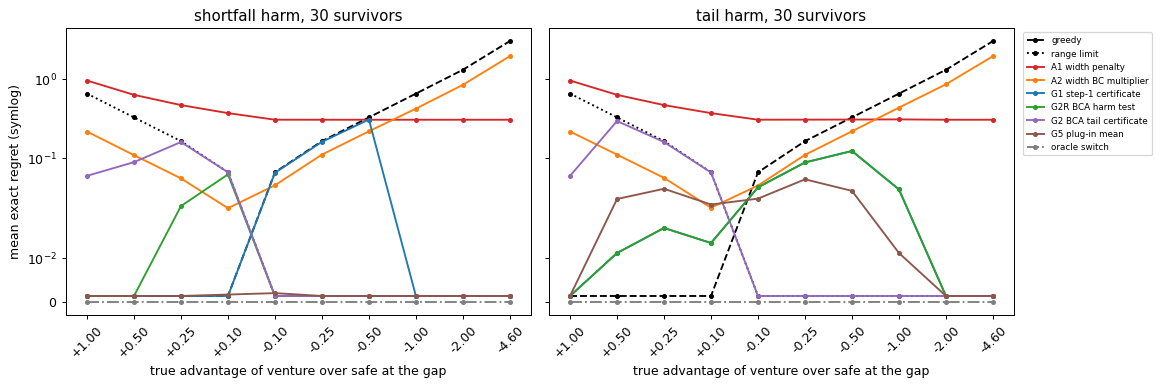

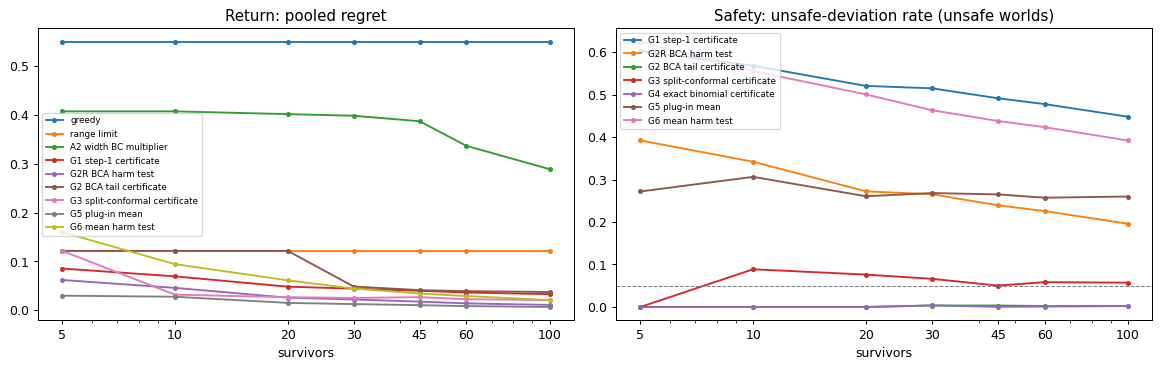

In [11]:
lines = ["greedy", "range limit", "A1 width penalty", "A2 width BC multiplier", "G1 step-1 certificate",
         "G2R BCA harm test", "G2 BCA tail certificate", "G5 plug-in mean", "oracle switch"]
styles = dict(zip(lines, ["k--", "k:", "C3-", "C1-", "C0-", "C2-", "C4-", "C5-", "C7-."]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
i30 = EVIDENCE.index(30)
for h, harm in enumerate(HARMS):
    ax = axes[h]
    for m in lines:
        ax.plot(range(len(ADV)), REG[:, i30, h, :, M[m]].mean(axis=0), styles[m], marker="o", ms=3, label=m)
    ax.set_xticks(range(len(ADV))); ax.set_xticklabels([f"{a:+.2f}" for a in ADV], rotation=45)
    ax.set_yscale("symlog", linthresh=0.02)
    ax.set_title(f"{harm} harm, 30 survivors")
    ax.set_xlabel("true advantage of venture over safe at the gap")
axes[0].set_ylabel("mean exact regret (symlog)")
axes[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for m in ["greedy", "range limit", "A2 width BC multiplier", "G1 step-1 certificate", "G2R BCA harm test",
          "G2 BCA tail certificate", "G3 split-conformal certificate", "G5 plug-in mean", "G6 mean harm test"]:
    axes[0].plot(EVIDENCE, [REG[:, i, ..., M[m]].mean() for i in range(len(EVIDENCE))], marker="o", ms=3, label=m)
for m in ["G1 step-1 certificate", "G2R BCA harm test", "G2 BCA tail certificate", "G3 split-conformal certificate",
          "G4 exact binomial certificate", "G5 plug-in mean", "G6 mean harm test"]:
    axes[1].plot(EVIDENCE, [DEV[:, i, ..., M[m]][unsafe_mask[:, i]].mean() for i in range(len(EVIDENCE))],
                 marker="o", ms=3, label=m)
axes[1].axhline(1 - BETA, color="grey", lw=0.8, ls="--")
axes[0].set_title("Return: pooled regret"); axes[1].set_title("Safety: unsafe-deviation rate (unsafe worlds)")
for ax in axes:
    ax.set_xscale("log"); ax.set_xticks(EVIDENCE); ax.set_xticklabels(EVIDENCE); ax.set_xlabel("survivors")
    ax.legend(fontsize=7)
fig.tight_layout(); plt.show()

## Checks

These checks confirm that the toy works as described; any failure stops the notebook. The last two printed lines confirm that BCA's width really is calibrated where it is measured, at logged actions.

In [12]:
# 1. Outcome laws normalize, and the gap mean is 1 + advantage in both shapes.
for harm in HARMS:
    for adv in ADVANTAGE:
        lw = gap_law(harm, adv)
        assert np.isclose(sum(p for p, _ in lw), 1) and all(p >= 0 for p, _ in lw)
        assert np.isclose(sum(p * m for p, m in lw), 1 + adv)
# 2. Worlds are paired: the same log and the same survivor random numbers.
tr, ca, sv = collect(0)
tr2, ca2, sv2 = collect(0)
assert all(np.array_equal(tr[k], tr2[k]) and np.array_equal(ca[k], ca2[k]) for k in tr)
assert np.allclose(survivor_rewards(sv, "shortfall", 0.5, 30) - survivor_rewards(sv, "shortfall", -1.0, 30), 1.5)
# 3. The critic never trains on survivors, and wants the gap action in every seed (asserted in run_seed).
q0, n0 = fit_critic(tr)
assert n0[1, 1, VENTURE] == 0
# 4. Regrets are non-negative, the oracle's is zero, and the gate rules differ from greedy only at the gap.
assert np.all(REG >= -1e-12) and np.allclose(REG[..., M["oracle switch"]], 0)
away = REG[..., M["greedy"]] - gap_cost(np.ones(DEV.shape[:4], dtype=bool))
for m in GATES:
    assert np.allclose(REG[..., M[m]], away + gap_cost(DEV[..., M[m]]))
# 5. Exact algebra behind test 4a: BCA's infinite-draw certificate equals the exact binomial test.
rng = np.random.default_rng([ROOT_SEED, 998])
for _ in range(2000):
    n = int(rng.integers(5, 120)); s = rng.standard_normal(n); a = float(rng.normal(1.0, 0.5))
    assert (bca_exact(s) <= a) == (binom_cdf(int((s > a).sum()), n, ALPHA) <= 1 - BETA)
# 6. The width is calibrated where it is measured: coverage of A1's widths on fresh logged rows.
sc0, un0 = fit_scale(tr, q0)
r0_ = bca_exact(np.abs(targets(ca, 0, q0) - q0[0, ca["c"], ca["a"][:, 0]]) / sc0[0, ca["c"], ca["a"][:, 0]])
r1_ = bca_exact(np.abs(targets(ca, 1, q0) - q0[1, ca["c"], ca["a"][:, 1]]) / sc0[1, ca["c"], ca["a"][:, 1]])
fresh = collect(10_000)[1]
for t, r_ in ((0, r0_), (1, r1_)):
    cov = (np.abs(targets(fresh, t, q0) - q0[t, fresh["c"], fresh["a"][:, t]])
           <= r_ * sc0[t, fresh["c"], fresh["a"][:, t]]).mean()
    print(f"A1 width coverage at recorded actions, stage {t}: {cov:.3f} (target at least {1 - ALPHA:.2f})")
    assert cov >= 0.85
print("All checks passed. Notebook seconds:", round(time.perf_counter() - START, 1))

A1 width coverage at recorded actions, stage 0: 0.902 (target at least 0.90)
A1 width coverage at recorded actions, stage 1: 0.935 (target at least 0.90)
All checks passed. Notebook seconds: 23.2


## What we found (written after the run)

| Test | Claim | Result | Verdict |
|---|---|---|---|
| 1 | BCA's width at every action (A1, A2) closes at least a quarter of the room | −2.50 and −2.09 of the room (worse than refusing thin data) | shelved |
| 2 | The step-1 gate (G1) closes at least half the room, and shuffled outcomes keep at most half of that | +0.58; shuffled outcomes keep none | alive |
| 3 | Comparing with the critic's claimed advantage beats step 1's margin against the rest | regret 0.028 against 0.051 | alive |
| 4a | BCA decides differently from the exact binomial test | 99.6% agreement | shelved |
| 4b | BCA's confidence makes deviations safer than plain split conformal | 5.5 points safer, against a 5-point bar | alive, narrowly |
| 4c | Safety needs a quantile, not an average | 28.8 points safer, against a 5-point bar | alive |

The kill rules were not edited: the fingerprint printed above matches the one recorded before the first run (`bb9e0325…dbc3`). One code fix came before any result existed; see *Technical notes* at the end.

### Shelved: BCA's width at every action (test 1)

- **The idea.** BCA's calibrated width puts caution where the critic is wrong. It is added either as a penalty at every action (A1) or as the production multiplier on the host's pull toward logged actions (A2).
- **What we tested (and the kill rule).** Both rules against refusing thin data, pooled over 200 seeds, both harm shapes, the ten worlds and seven evidence sizes. Each is shelved if it closes less than a quarter of the room.
- **What happened.** Both did worse than refusing thin data: regret 0.425 (A1) and 0.376 (A2), against 0.122. A2 did beat the plain host (0.494), but through blanket caution: with 30 survivors it ventured at the gap in about two thirds of seeds in every world. A1's gap decision changed across the ten worlds in at most 1% of seeds. A2's changed in at most 5% until there were 60 or more survivors. The widths were still calibrated where they are measured: they covered 90.2% and 93.5% of fresh logged rows, against a 90% target.
- **Why.** The width is measured at logged actions, and the gap has none, so the width there comes from the scale, not from the gap's outcomes. The survivors are a small share of a pooled bank of about 600 rows, too few to move the one shared threshold. Meanwhile, the penalty also hits good actions that are merely noisy. A1 refuses venture at the last step in context 0 (outcomes 0 or 3) and at the first step in context 1 (outcomes −0.5 or 1.1), which costs about 0.30 of regret.

### Shelved: "BCA decides differently from the exact binomial test" (test 4a)

- **The idea.** BCA's Bayesian posterior adds information that a classical test lacks.
- **What we tested (and the kill rule).** The BCA tail certificate (G2) against the exact binomial certificate (G4), case by case. Shelved if they agree in at least 99% of cases.
- **What happened.** They agreed in 99.6%. The rest are random-sampling slips with 1,000 draws. With 100,000 draws, the table near the top agrees in every case, and check 5 confirms the match exactly on 2,000 random cases.
- **Why.** With equal weights, BCA's threshold is one of the sorted scores, picked by a binomial tail. That is a textbook tolerance limit; see *Technical notes*.

### Information only (written after the run)

The next cell prints three things:

1. For each world, with 30 survivors, the share of seeds in which each rule ventures at the gap. A * marks unsafe worlds. Venture is better on average when the advantage is above 0.
2. For the worst unsafe world, the share of seeds that venture there, by number of survivors.
3. How spread out the step-1 gate's comparison group is across seeds.

In [13]:
# Added after the run, information only: per-world decisions at 30 survivors, the worst single unsafe world,
# and the spread of the reference group that the step-1 gate compares against.
i30 = EVIDENCE.index(30)
show = ["range limit", "A2 width BC multiplier", "G1 step-1 certificate", "G2R BCA harm test",
        "G2 BCA tail certificate", "G3 split-conformal certificate", "G5 plug-in mean"]
for h, harm in enumerate(HARMS):
    print(f"{harm}: share of seeds that venture at the gap with 30 survivors "
          "(* unsafe world; venture is better on average when the advantage is above 0)")
    print(f"{'rule':31}" + "".join(f"{a:+7.2f}{'*' if UNSAFE[h, w] else ' '}" for w, a in enumerate(ADV)))
    for m in show:
        print(f"{m:31}" + "".join(f"{DEV[:, i30, h, w, M[m]].mean():7.2f} " for w in range(len(ADV))))
    print()
print("Worst single unsafe world: share of seeds that venture there, by evidence size")
for m in ["G2 BCA tail certificate", "G4 exact binomial certificate", "G3 split-conformal certificate",
          "G2R BCA harm test", "G5 plug-in mean"]:
    worst = [DEV[:, k, :, :, M[m]].mean(axis=0)[UNSAFE].max() for k in range(len(EVIDENCE))]
    print(f"{m:31}", "  ".join(f"n={ne}: {v:.2f}" for ne, v in zip(EVIDENCE, worst)))
med, low, share = [], [], []
for seed in range(N_SEEDS):
    train, cal, _ = collect(seed)
    q, _ = fit_critic(train)
    rng = np.random.default_rng([ROOT_SEED, seed, 1])
    rng.standard_exponential((DRAWS, max(EVIDENCE) + 1))   # the gap's draws, as in run_seed
    s_rest = q[1, cal["c"], cal["a"][:, 1]] - cal["r"][:, 1]
    cross = bca(s_rest, rng.standard_exponential((DRAWS, s_rest.size + 1)))[1]
    med.append(np.median(cross)); low.append(np.quantile(cross, 0.05))
    share.append(np.mean((cal["c"] == 0) & (cal["a"][:, 1] == VENTURE) & (cal["r"][:, 1] < 1.5)))
print(f"\nThe step-1 gate's reference group (all other final-step calibration rows), over {N_SEEDS} seeds:")
print(f"  posterior median of its 90% crossing: mean {np.mean(med):.2f}, from {min(med):.2f} to {max(med):.2f}")
print(f"  5% posterior quantile of that crossing: mean {np.mean(low):.2f}")
print(f"  share of its rows that are the noisy cell's low outcomes (over-prediction near 1.5): {np.mean(share):.3f}")

shortfall: share of seeds that venture at the gap with 30 survivors (* unsafe world; venture is better on average when the advantage is above 0)
rule                             +1.00   +0.50   +0.25*  +0.10*  -0.10*  -0.25*  -0.50*  -1.00*  -2.00*  -4.60*
range limit                       0.00    0.00    0.00    0.00    0.00    0.00    0.00    0.00    0.00    0.00 
A2 width BC multiplier            0.67    0.67    0.67    0.67    0.67    0.67    0.67    0.65    0.65    0.65 
G1 step-1 certificate             1.00    1.00    1.00    1.00    0.98    0.98    0.94    0.00    0.00    0.00 
G2R BCA harm test                 1.00    1.00    0.85    0.06    0.00    0.00    0.00    0.00    0.00    0.00 
G2 BCA tail certificate           0.91    0.73    0.03    0.00    0.00    0.00    0.00    0.00    0.00    0.00 
G3 split-conformal certificate    1.00    0.99    0.35    0.01    0.00    0.00    0.00    0.00    0.00    0.00 
G5 plug-in mean                   1.00    1.00    1.00    0.99    0.01 

## What the results say

1. **The useful signal is the risky action's own outcomes.** Every rule that read the survivors' held-out outcomes closed 38% to 87% of the room. With shuffled outcomes, the step-1 gate and the harm test did worse than refusing thin data, and the tail certificate only matched it.
2. **What a gate compares against matters more than BCA's posterior.**
   - The step-1 gate asks whether the survivors' over-predictions are clearly worse than those of every other last-step row. About 10.7% of those other rows are a noisy cell's low outcomes, right at the 10% line, so the comparison point is unstable. Its posterior median ran from 0.35 to 1.50 across seeds.
   - A wide comparison point lets bad deviations through. In the shortfall shape, the step-1 gate ventured in 94–98% of seeds at advantages −0.10 to −0.50, where venture is worse than safe. Comparing with the critic's claimed advantage (about 0.5) stopped all of those, and regret fell from 0.051 to 0.028.
   - In the tail shape, the two forms made the same decisions. In the first figure, the step-1 line hides under the harm test's.
   - A quiet local comparison group (context-1 rows only) got most of the way, to 0.033. The margin barely mattered: regret 0.049 to 0.054 for margins 0 to 0.25.
   - In ThrusterChain, step 1's statistic stayed within 0.06 of zero in the no-stall world (−0.058 to −0.016 in sample). Its comparison group was quiet, so the same rule worked there.
3. **Compared with the claimed advantage, the critic drops out.** The score is q(venture) − outcome and the claimed advantage is q(venture) − q(safe). So "score at most the claimed advantage" is the same as "outcome at least q(safe)". The gate is really a test of the survivors' raw outcomes against the safe action's value. The critic estimates that value well, because the safe action is in the data.
4. **The right statistic depends on the goal.**
   - **For return,** the survivors' plain average against the safe action's value (G5) was best at every evidence size. Its regret was 0.016, and 0.030 even with 5 survivors. The BCA harm test (G2R) came second at 0.028. A 90% share is the wrong question for an average. In the shortfall shape at advantage +0.10, the harm test ventured in only 6% of seeds, although venture is better on average there.
   - **For safety,** meaning "deviate only if at most 10% of outcomes fall below the safe action": BCA's tail certificate (G2) and its exact twin (G4) ventured in at most 3% of seeds in every unsafe world, at every evidence size. Plain split conformal (G3) reached 32–38% in its worst world, because its guarantee holds on average over data sets, not with 95% confidence for the data in hand. The plain average is not built for this. It ventured in nearly every seed in the shortfall worlds that are unsafe but better on average, and in 12–46% of seeds in tail-shape worlds that are worse on average.
   - **The certificate's price** was 0.060 more regret than the plain average. It refused good ventures with rare catastrophes: at +0.50 in the tail shape, it ventured in only 10% of seeds. It cannot decide at all below 29 survivors.
5. **BCA's own part is narrow.** With equal weights, BCA is a classical tolerance limit (test 4a). What it adds over the plain rivals is what its answer means: a 90% share, with 95% confidence for the data in hand. That suits a safety certificate at a deviation, not average return. The only part of BCA that is not a textbook test is its weighting. Weighting matters only when a gate's survivors come from a different mix of states than deployment will visit. Here the gap is a single cell, so weighting cannot matter; it is untested.

## What this means for BCA (exploratory; toy seeds only)

1. **Use BCA as a gate at deviations, not as a width in the training loss.** Stop using the width doses as the vehicle for BCA claims: the behavior-cloning multiplier in TD3+BC and ReBRAC, and the conservative-penalty multiplier in CQL. Test 1 here and ThrusterChain's earlier results agree that the width cannot respond where the decision is made.
2. **Compare with the fallback's value, not with the rest of the data plus a margin.** Where the actor wants a command the data rarely contain, deviate only if a bound on the held-out survivors' outcomes beats the fallback command's value. The critic estimates that value on data. This removes the 0.10 margin, which is a free parameter, and the dependence on unrelated noisy rows.
3. **Match the statistic to the claim.**
   - If the claim is about return, use the survivors' average, or a test on it; BCA's tail certificate is not needed. The follow-up notebook, [bca_mean_gate_toy.ipynb](bca_mean_gate_toy.ipynb), tests a BCA gate on the average.
   - If the claim is that deviations rarely do worse than the fallback, use BCA's tail certificate. Deviate only when it certifies, with 95% confidence, that at least 90% of outcomes beat the fallback. Make the per-world unsafe-deviation rate the main measure, and report return as its cost.
4. **Compute equal-weight BCA exactly.** Use the binomial formula instead of 1,000 random draws. The threshold is the same in theory, but exact arithmetic has no slips near the boundary: with 1,000 draws, only 4 of 8 score sets agreed at n = 28 and 29. The evidence floor also drops from 36 rows (production's allowance for sampling error) to 29. Keep random draws for weighted banks only.
5. **Use weights only where they differ.** The one place BCA could beat the exact binomial test is a gate whose survivors come from a different state mix than deployment. That needs its own test and kill rule.
6. **Describe it plainly.** With equal weights, BCA's threshold is a textbook tolerance limit. A claim that the Bayesian posterior adds value cannot be supported; a claim of a per-decision safety certificate can.

## What this does not show

- These are toy seeds, with two harm shapes and one known gap cell. Nothing here is ThrusterChain evidence or confirmatory.
- The gap is given. In a real host, the gate must find the deviations and group survivors by similarity, and every split costs evidence. Step 1's ThrusterChain gate had 28–59 survivors per seed-world, right at the floor of 29.
- ThrusterChain's stall is shortfall-shaped. In shortfall worlds the quantile and average gates mostly agree, and the plain average is better for return. Showing BCA's distinct value there would need tail-shaped harm and a safety measure. Any such change to step 2 needs a new pre-registration, approved at your terminal.

## Technical notes

- **The textbook identity.** With equal weights, BCA's 95%-credible threshold is the score with x scores above it, for the largest x with P(Binomial(n, 0.1) ≤ x) ≤ 0.05. That is the exact one-sided binomial (Clopper–Pearson) test. It is also the training-conditional split-conformal bound (Vovk, 2012) and Wilks' (1941) distribution-free tolerance limit. Wilks' sample size for a one-sided 90% limit at 95% confidence is 29, because 0.9^29 = 0.047 is the first power of 0.9 below 0.05.
- **BCA's re-implementation.** `bca` follows `calibration/wbcp.py`. It puts random Dirichlet masses on the sorted scores plus one worst-case test point, finds each draw's 90% crossing and the 95%-credible crossing, and takes the larger of that and the plain empirical quantile.
- **The width's scale.** Each cell's residual spread from training rows, shrunk toward the pooled spread with 5 pseudo-rows. This replaces the first notebook's 1/√count.
- **The pre-result code fix.** The first execution stopped at the start of the main loop, on a check of mine that was too strict. It required every posterior draw for the 90-row local comparison group to cross, but a draw fails to cross with probability 0.9^90, about 1 in 13,000. The check now covers only the main comparison group of about 600 rows. Nothing else changed.
- **Rewritten explanations.** The explanations were rewritten in plainer language after the run. Code, kill rules and printed results are unchanged, and rerunning reproduces every number exactly. One sentence was corrected: the plain average ventured in nearly every seed only in the shortfall worlds that are unsafe but better on average, not in all such worlds.